# Wan 2.2: generating video from text

[Wan 2.2](https://github.com/Wan-Video/Wan2.2) (Alibaba, July 2025) is an open **text-to-video** diffusion model:
give it a sentence, and it generates a few seconds of video. This notebook uses `Wan-AI/Wan2.2-TI2V-5B`, the version
that fits on a single 16 GB GPU, through the `diffusers` library (the `-Diffusers` copy of the weights, Apache 2.0
license). "TI2V" means it can start from text, or from an image that becomes the first frame; this notebook does
both. (The larger Wan 2.2 models, A14B,
use two 14-billion-parameter transformers — far too large for the course's GPUs.)

Like the image diffusion models of this module (Stable Diffusion), it starts from random noise and removes it step by
step, guided by the text — but the noise has an extra **time** axis, so it denoises all frames of the video together.
The pipeline has four parts:

| part | model | role |
|---|---|---|
| text encoder | umT5-XXL (5.7 B parameters) | turns the prompt into 512 vectors |
| transformer | Wan DiT (5.0 B) | predicts how to remove the noise, step by step |
| VAE | Wan 2.2 VAE (0.7 B) | compresses video 4× in time and 16 × 16 in space, and decodes the result back to pixels |
| scheduler | UniPC (flow matching) | decides how much noise to remove at each step |

In [1]:
import base64
import subprocess
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from huggingface_hub.utils import logging as hub_logging
from IPython.display import HTML
from diffusers.utils import logging as diffusers_logging
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()  # no warning about downloading without a Hugging Face login (not needed here)
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecations inside the libraries
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, torch.cuda.get_device_name() if device == "cuda" else "(this notebook needs a GPU instance)")

device: cuda NVIDIA A100-SXM4-40GB


## 1. Loading the pipeline

The transformer and the text encoder are loaded in **16-bit** floats (half the memory of 32-bit; Wan keeps its
normalization layers in 32 bits by itself), the VAE in 32 bits for clean decoding. `enable_model_cpu_offload()` keeps
the parts in CPU memory and moves each one to the GPU only while it runs, so the 11 GB text encoder and the 10 GB
transformer never need the GPU at the same time, and `vae.enable_tiling()` decodes the video in tiles. This is what
makes the model fit on a 16 GB GPU.

In [2]:
from diffusers import AutoencoderKLWan, WanPipeline

REPO = "Wan-AI/Wan2.2-TI2V-5B-Diffusers"
CACHE = Path("/tmp/huggingface")  # not the home folder: it's limited to 10 GB

start = time.time()
vae = AutoencoderKLWan.from_pretrained(REPO, subfolder="vae", dtype=torch.float32, cache_dir=CACHE)
pipe = WanPipeline.from_pretrained(REPO, vae=vae, dtype=torch.float16, cache_dir=CACHE)
pipe.enable_model_cpu_offload()
pipe.vae.enable_tiling()
pipe.set_progress_bar_config(disable=True)
print(f"loaded in {time.time() - start:.0f} s (the first time includes the download)")

{name: f"{type(part).__name__}: {sum(p.numel() for p in part.parameters()) / 1e9:.2f} B parameters"
 for name, part in pipe.components.items() if hasattr(part, "parameters")}

loaded in 4 s (the first time includes the download)


{'vae': 'AutoencoderKLWan: 0.70 B parameters',
 'text_encoder': 'UMT5EncoderModel: 5.68 B parameters',
 'transformer': 'WanTransformer3DModel: 5.00 B parameters'}

## 2. Generating a video

The main settings:

- `height`, `width`: the 5B model is trained for 720p (**704 × 1280**); both must be multiples of 32. We use
  **480 × 832**, which is about twice as fast and still looks good;
- `num_frames`: must be $4k + 1$ (the VAE compresses 4 frames into one); the model makes up to 121 frames —
  5 seconds at 24 frames per second. We use 49 frames (2 s) to keep it fast;
- `num_inference_steps`: more denoising steps, more detail, slower;
- `guidance_scale`: how strongly to follow the prompt (*classifier-free guidance*: each step is computed with and
  without the prompt, and the difference is amplified);
- `negative_prompt`: what to steer away from;
- `generator`: the random seed of the starting noise — the same seed and settings give the same video.

In [3]:
NEGATIVE = "blurry, low quality, distorted, static, still picture, worst quality, watermark, text, subtitles"


def generate(prompt, seed=0, num_frames=49, steps=40, guidance=5.0, height=480, width=832):
    start = time.time()
    torch.cuda.reset_peak_memory_stats()
    frames = pipe(prompt=prompt, negative_prompt=NEGATIVE, height=height, width=width, num_frames=num_frames,
                  num_inference_steps=steps, guidance_scale=guidance,
                  generator=torch.Generator("cpu").manual_seed(seed), output_type="np").frames[0]
    print(f"{frames.shape[0]} frames of {frames.shape[2]} × {frames.shape[1]} in {time.time() - start:.0f} s, "
          f"peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
    return frames                                   # (frames, height, width, 3), values in [0, 1]


def show_video(frames, fps=24):
    """Encodes the frames as an H.264 mp4 (with ffmpeg) and embeds it in the notebook."""
    height, width = frames.shape[1:3]
    pixels = (frames * 255).round().astype(np.uint8)
    mp4 = subprocess.run(["ffmpeg", "-v", "error", "-f", "rawvideo", "-pix_fmt", "rgb24", "-s", f"{width}x{height}",
                          "-r", str(fps), "-i", "-", "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "23",
                          "-movflags", "frag_keyframe+empty_moov", "-f", "mp4", "-"],
                         input=pixels.tobytes(), capture_output=True, check=True).stdout
    return HTML(f'<video width="{width}" controls loop autoplay muted>'
                f'<source src="data:video/mp4;base64,{base64.b64encode(mp4).decode()}" type="video/mp4"></video>')


def show_frames(frames, count=6, title=""):
    fig, axes = plt.subplots(1, count, figsize=(17, 2.2), layout="constrained")
    for ax, index in zip(axes, np.linspace(0, len(frames) - 1, count).astype(int)):
        ax.imshow(frames[index])
        ax.set_title(f"frame {index} ({index / 24:.2f} s)", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=10)
    plt.show()

49 frames of 832 × 480 in 70 s, peak GPU memory 13.5 GB


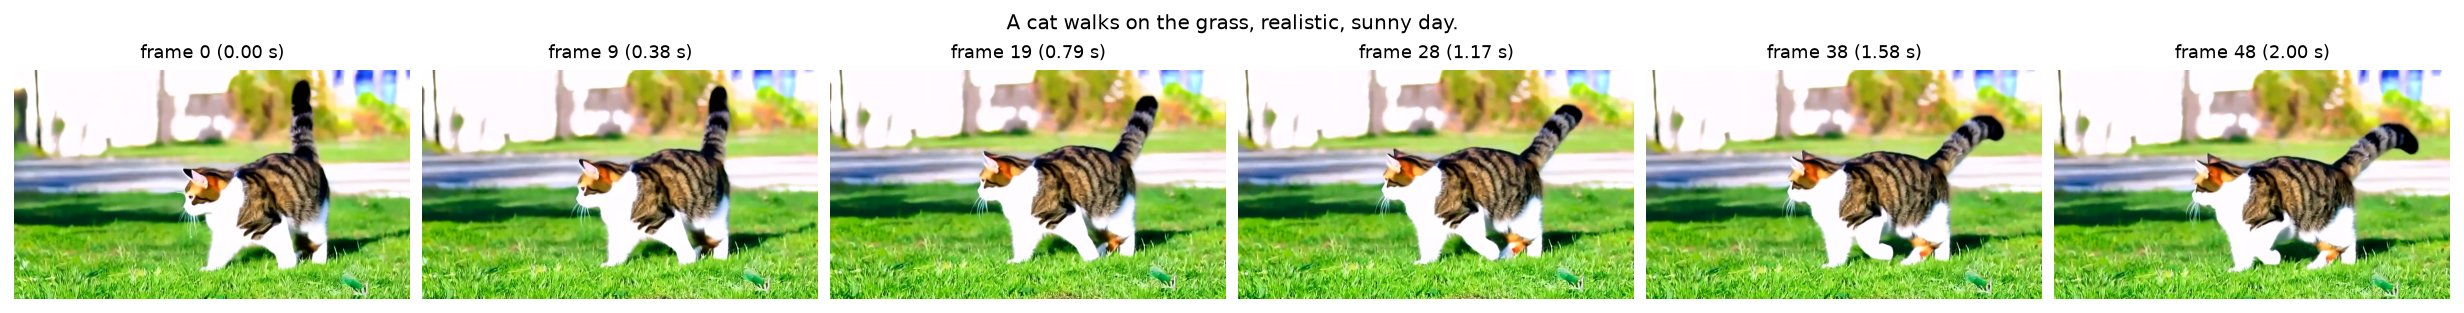

In [4]:
cat = generate("A cat walks on the grass, realistic, sunny day.")
show_frames(cat, title="A cat walks on the grass, realistic, sunny day.")
show_video(cat)

Longer, more specific prompts give more control: the subject, the action, the setting, the light, and the camera.

49 frames of 832 × 480 in 74 s, peak GPU memory 13.5 GB


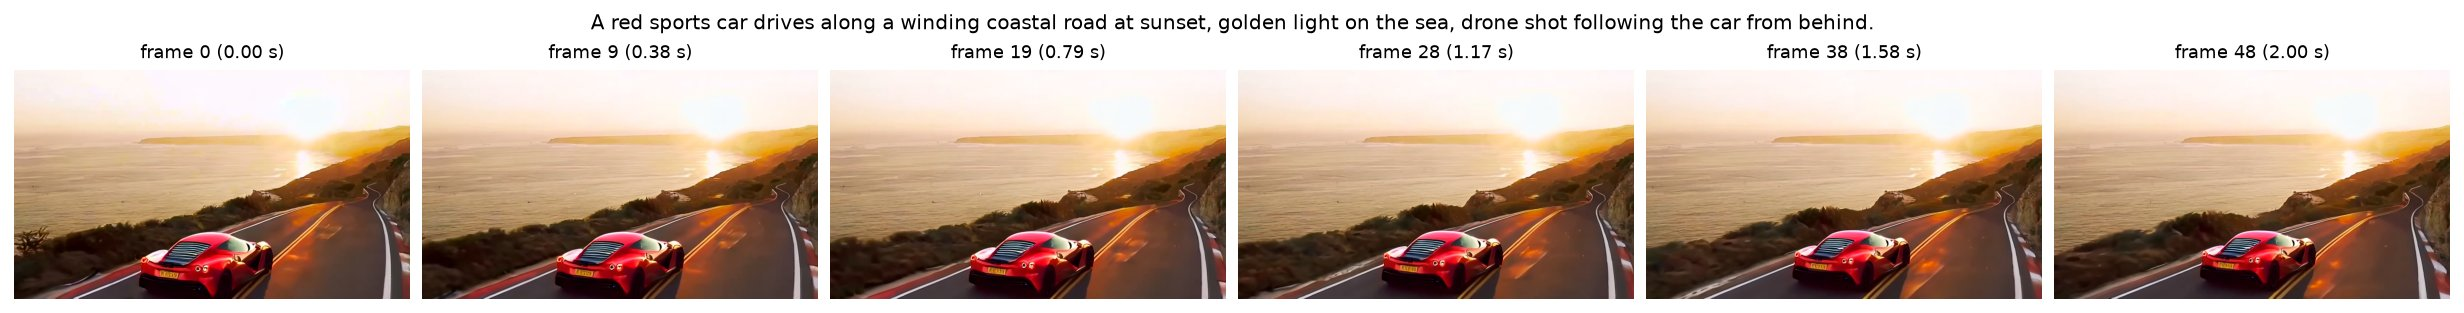

In [5]:
prompt = ("A red sports car drives along a winding coastal road at sunset, golden light on the sea, "
          "drone shot following the car from behind.")
car = generate(prompt, seed=1)
show_frames(car, title=prompt)
show_video(car)

### The seed

The starting noise decides much of the result: the same prompt with a different seed is a different video.

49 frames of 832 × 480 in 71 s, peak GPU memory 13.5 GB


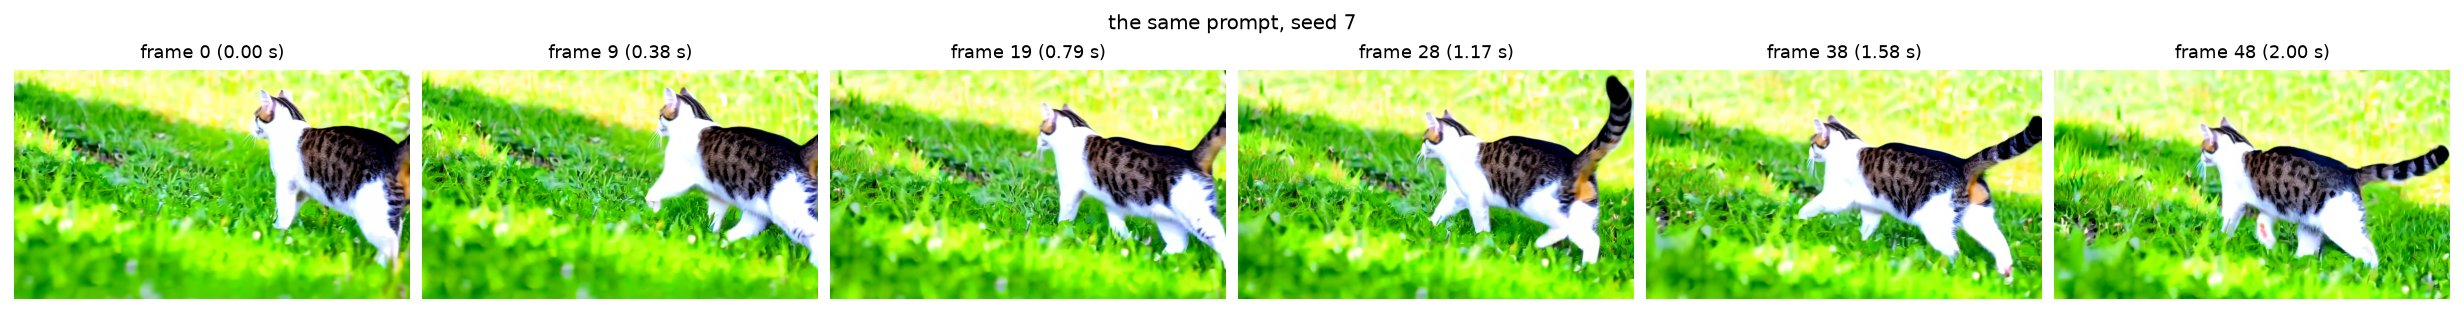

In [6]:
other_cat = generate("A cat walks on the grass, realistic, sunny day.", seed=7)
show_frames(other_cat, title="the same prompt, seed 7")

## 3. From an image to a video

The same model can start from a picture: the image becomes the **first frame**, and the prompt describes what happens
next. `WanImageToVideoPipeline` uses the same text encoder, transformer and VAE, so we build it from the parts already
loaded instead of loading them again. (Its `from_pipe(pipe)` shortcut would convert all parts to 32-bit floats —
twice the memory and several times slower — so we pass the parts directly.)

Inside, the VAE encodes the image into the first latent frame, and that frame is kept clean during denoising: its
tokens get noise level 0, all others the current level (the per-token timesteps of the WanVideoArchitecture notebook).

49 frames in 71 s, peak GPU memory 13.9 GB
first frame vs the image: mean difference 0.029 (of 1)


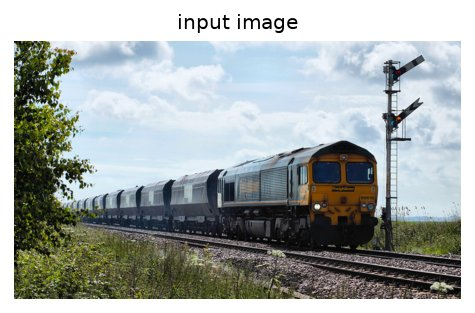

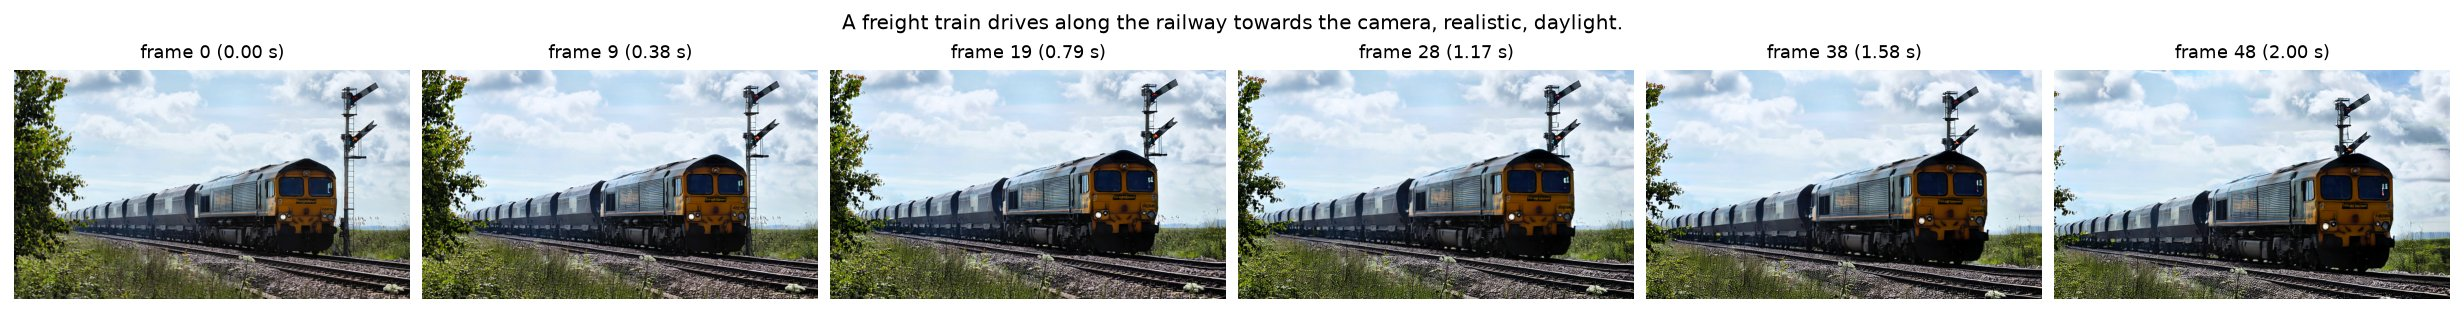

In [7]:
from diffusers import WanImageToVideoPipeline
from PIL import Image
import requests

image_to_video = WanImageToVideoPipeline(**pipe.components, expand_timesteps=True)
image_to_video.enable_model_cpu_offload()
image_to_video.set_progress_bar_config(disable=True)

# one simple object with a simple motion: a freight train (COCO val2017 90155), cropped to the 832 × 480 of the video
url = "https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/000000090155.jpg"
photo = Image.open(requests.get(url, stream=True).raw).convert("RGB")
crop = round(photo.width * 480 / 832)
photo = photo.crop((0, (photo.height - crop) // 2, photo.width, (photo.height - crop) // 2 + crop)).resize((832, 480))

prompt = "A freight train drives along the railway towards the camera, realistic, daylight."
start = time.time()
torch.cuda.reset_peak_memory_stats()
# Encode the prompt first and free the GPU: otherwise the 11 GB text encoder is still on the GPU while the VAE
# encodes the image, which needs more than the 16 GB of a T4.
with torch.no_grad():
    prompt_embeds, negative_embeds = image_to_video.encode_prompt(prompt=prompt, negative_prompt=NEGATIVE, device=device,
                                                                  max_sequence_length=512)
image_to_video.maybe_free_model_hooks()
train = image_to_video(image=photo, prompt_embeds=prompt_embeds, negative_prompt_embeds=negative_embeds, height=480,
                      width=832, num_frames=49, num_inference_steps=40, guidance_scale=5.0,
                      generator=torch.Generator("cpu").manual_seed(0), output_type="np").frames[0]
print(f"{len(train)} frames in {time.time() - start:.0f} s, peak GPU memory {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
print(f"first frame vs the image: mean difference {np.abs(train[0] - np.asarray(photo) / 255).mean():.3f} (of 1)")

fig, ax = plt.subplots(figsize=(4, 2.4))
ax.imshow(photo)
ax.set_title("input image", fontsize=10)
ax.axis("off")
plt.show()
show_frames(train, title=prompt)
show_video(train)

## Summary

- `WanPipeline.from_pretrained(...)` loads the text encoder, transformer, VAE and scheduler; `enable_model_cpu_offload()`
  and `vae.enable_tiling()` make it fit on a 16 GB GPU;
- `pipe(prompt=..., height=480, width=832, num_frames=4k+1, num_inference_steps=..., guidance_scale=...)` returns the
  frames; the seed of the `generator` makes it reproducible;
- `WanImageToVideoPipeline(**pipe.components, expand_timesteps=True)` reuses the loaded parts: `image=...` becomes the
  first frame, the prompt describes the motion;
- the full 720p quality: `generate(prompt, height=704, width=1280)` — about twice as slow; on a T4 GPU
  (`ml.g4dn.4xlarge`), expect several minutes per 2-second video at 480p, and more for longer or larger videos.